# Lab Assignment 13

**Prerequisite:** the class demo notebook *ICL_and_Instruction_Finetuning_Demo.ipynb*  
**Runtime:** Google Colab with a T4 GPU (about 10–15 minutes of GPU time per task)

Each task is a small, real NLP problem: you design the solution, run the experiments and explain what you found. Only data loading and evaluation functions are given, so that everyone's numbers are comparable.

## Rules
- Use only the models named in each task.
- You may reuse any code from the class demo. Cite any other source.
- Fix random seeds and report the settings you used.
- The two tasks are independent, so you can restart the runtime between them.

## Submission
Submit this notebook as `.ipynb` **with all outputs visible**.

## 0. Setup

In [1]:
!pip install -q transformers datasets accelerate sentence-transformers scikit-learn

In [2]:
import re, time, random, gc, sqlite3, warnings
from collections import Counter
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForCausalLM, DataCollatorForSeq2Seq,
                          Trainer, TrainingArguments)

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 300)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)


def set_seed(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def clear_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def load_causal_lm(name):
    """Load a decoder-only model in fp32 (numerically safe on a T4) and its tokenizer."""
    tok = AutoTokenizer.from_pretrained(name)
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    model = AutoModelForCausalLM.from_pretrained(name).to(device).eval()
    return tok, model


@torch.no_grad()
def generate_batch(model, tok, prompts, max_new_tokens=64, batch_size=8, stop_strings=None, desc="generating"):
    """Greedy, batched generation. Returns only the new text for each prompt, cut at the first stop string."""
    kwargs = dict(stop_strings=stop_strings, tokenizer=tok) if stop_strings else {}
    old_side, tok.padding_side = tok.padding_side, "left"
    outputs = []
    for i in tqdm(range(0, len(prompts), batch_size), desc=desc, leave=False):
        enc = tok(prompts[i:i + batch_size], return_tensors="pt", padding=True).to(device)
        gen = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                             pad_token_id=tok.pad_token_id, **kwargs)
        for row in gen[:, enc["input_ids"].shape[1]:]:
            text = tok.decode(row, skip_special_tokens=True)
            for s in (stop_strings or []):
                text = text.split(s)[0]
            outputs.append(text.strip())
    tok.padding_side = old_side
    return outputs

/Users/teesharamchandani/Downloads/Lab-13/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cpu


> **Runtime note.** This notebook was executed end to end on an Apple M3 (CPU, PyTorch 2.5.1,
> transformers 4.57) rather than on a Colab T4. The code is unchanged and device-agnostic: `device`
> is set in the cell above, and the `use_cpu` flag in Task 2 only keeps `Trainer` on that same
> device. Only the timing numbers depend on this (`sec_per_example`, `sec_per_query` and the
> training minutes); every accuracy is unaffected, because all decoding is greedy and all seeds are
> fixed. Total runtime: about 45 minutes.

---
# Section A: In-Context Learning

## Task 1. A news-topic classifier with zero training (50 marks)

**Scenario.** A news website wants to tag articles as **World**, **Sports**, **Business** or **Sci/Tech**. It has only 200 labelled articles and no budget to train a model. Build the best classifier you can using **only in-context learning**, then decide whether it is actually a better choice than a simple classical model.

**Constraints**
- Model: `Qwen/Qwen2.5-0.5B` (base). No weight updates.
- Demonstrations may only come from `ag_pool`, with **at most 8 per prompt**.
- Every prediction must be one of the four classes. Report final numbers on `ag_test` using `report_classification`.

**What you must do**
1. **Baselines.** Evaluate zero-shot and 8 randomly chosen demonstrations.
2. **Retrieval-based demonstrations.** For each test article, choose the 8 most similar articles from `ag_pool` as demonstrations, using sentence embeddings from `sentence-transformers/all-MiniLM-L6-v2`. Compare with random selection.
3. **Classical baseline.** Train TF-IDF + logistic regression on the same 200 articles.
4. **Error analysis.** Show the confusion matrix of your best system and explain 3 of its mistakes.

**Analysis questions** (about 250 words in total)
- (a) Did retrieval-based demonstrations beat random ones? Why do you think similar examples help?
- (b) Which classes get confused most often, and why might that be?
- (c) Compare your best ICL system with logistic regression on accuracy **and** speed (seconds per article). Which would you deploy for this website, and why?



In [3]:
ag = load_dataset("fancyzhx/ag_news")
AG_LABELS = ["World", "Sports", "Business", "Sci/Tech"]

ag_test = ag["test"].shuffle(seed=0).select(range(200))
_train = ag["train"].shuffle(seed=1)
ag_pool = _train.select(range(200))          # the ONLY labelled data you may use
ag_dev = _train.select(range(200, 300))      # use for design decisions (prompt format, label words)

for name, ds in [("pool", ag_pool), ("dev", ag_dev), ("test", ag_test)]:
    counts = Counter(ds["label"])
    print(f"{name:5s}", {AG_LABELS[k]: counts[k] for k in range(4)})
print("\nExample:", ag_pool[0])

pool  {'World': 48, 'Sports': 53, 'Business': 49, 'Sci/Tech': 50}
dev   {'World': 23, 'Sports': 26, 'Business': 33, 'Sci/Tech': 18}
test  {'World': 49, 'Sports': 47, 'Business': 50, 'Sci/Tech': 54}

Example: {'text': "Brown feels fortunate to have a hand in series Thirty-two pitches. That's a couple innings for most pitchers -- or two lengthy Johnny Damon at-bats. It amounted to Kevin Brown's entire body of work against the Red Sox Sept. 26. It was not a pretty sight.", 'label': 1}


In [4]:
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

RESULTS_T1 = []   # append the dict returned by report_classification for every system


def report_classification(y_true, y_pred, method, sec_per_example=None, show_cm=False):
    """Fixed evaluation for Task 1. y_true / y_pred are lists of label ids (0-3)."""
    res = {"method": method,
           "accuracy": accuracy_score(y_true, y_pred),
           "macro_f1": f1_score(y_true, y_pred, average="macro"),
           "sec_per_example": sec_per_example}
    if show_cm:
        ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=list(range(4)), display_labels=AG_LABELS,
                                                cmap="Blues", xticks_rotation=45)
        plt.title(method); plt.show()
    return res

### Task 1: Your solution
Add as many code and text cells as you need.

### Plan and settings

| | choice | why |
|---|---|---|
| model | `Qwen/Qwen2.5-0.5B` (base, frozen) | required by the task |
| decision rule | rank classification: one forward pass per article, compare `P(first token of label word)` | a base model given a prompt does not reliably *write* a label; scoring the four label words makes every prediction one of the four classes and costs one forward pass |
| text | HTML entities / stray `\\` removed, truncated to 400 characters | AG News is raw newswire; shorter demos mean 8 of them still fit comfortably |
| label words | chosen on `ag_dev` out of two candidate verbalizers | the label word matters as much as the examples |
| k | 0 / 8 on the test set, k-curve measured on `ag_dev` | the task allows at most 8 |
| demo order (retrieval) | increasing similarity, most similar last | the demonstrations nearest the query position have the strongest influence |
| seeds | 0 everywhere, greedy decoding | reproducibility |

`ag_dev` is used for every design decision; `ag_test` is only touched by the four final systems.

In [5]:
# ---------------------------------------------------------------------------
# Task 1 - settings
# ---------------------------------------------------------------------------
# Everything below is greedy / deterministic, seeds fixed at 0.
#   model          : Qwen/Qwen2.5-0.5B (base, no weight updates)
#   decision rule  : rank classification over the 4 label words (see below)
#   demos          : at most 8, always taken from ag_pool
SEED = 0
K_MAX = 8
set_seed(SEED)
print("Device:", device, "| torch", torch.__version__)

tok_q, model_q = load_causal_lm("Qwen/Qwen2.5-0.5B")
print("Qwen2.5-0.5B loaded |", sum(p.numel() for p in model_q.parameters()) / 1e6, "M params")

Device: cpu | torch 2.5.1


Qwen2.5-0.5B loaded | 494.032768 M params


In [6]:
# ---------------------------------------------------------------------------
# Text cleaning + prompt format
# ---------------------------------------------------------------------------
# AG News text is raw newswire: it contains "\" instead of line breaks, HTML
# entities (#39;) and stray tags. Cleaning it costs nothing and makes the
# prompt shorter, which matters when 8 demonstrations share one context.
_ENT = {"lt": "<", "gt": ">", "amp": "&", "quot": '"', "nbsp": " ", "#39": "'"}


def clean(text, max_chars=400):
    t = text.replace("\\", " ")
    t = re.sub(r"&?(lt|gt|amp|quot|nbsp|#39);", lambda m: _ENT[m.group(1)], t)
    t = re.sub(r"<[^>]+>", " ", t)
    return re.sub(r"\s+", " ", t).strip()[:max_chars]


# Two candidate verbalizers (label words). "surface" uses the dataset's own
# names, "natural" uses words a journalist would use; which one the model
# prefers is an empirical question, so we settle it on ag_dev.
VERBALIZERS = {"surface": ["World", "Sports", "Business", "Sci/Tech"],
               "natural": ["Politics", "Sports", "Business", "Technology"]}

INSTRUCTION = "Classify the topic of each news article as {opts}.\n\n"


def make_prompt(text, demos, verb, instruction=True):
    """demos: list of (text, label_id) pairs, written in the order given."""
    p = INSTRUCTION.format(opts=", ".join(verb)) if instruction else ""
    for t, lab in demos:
        p += f"Article: {clean(t)}\nTopic: {verb[lab]}\n\n"
    return p + f"Article: {clean(text)}\nTopic:"


print(make_prompt(ag_test["text"][0], [(ag_pool["text"][0], ag_pool["label"][0])], VERBALIZERS["surface"]))

Classify the topic of each news article as World, Sports, Business, Sci/Tech.

Article: Brown feels fortunate to have a hand in series Thirty-two pitches. That's a couple innings for most pitchers -- or two lengthy Johnny Damon at-bats. It amounted to Kevin Brown's entire body of work against the Red Sox Sept. 26. It was not a pretty sight.
Topic: Sports

Article: McTeer: Lonesome Dove to be an Aggie NEW YORK (CNN/Money) - A New Economy champion, a lover of the Texas picker poets who write lovesick country songs...and, oh, by the way, a member of the Federal Reserve system for 36 years.
Topic:


In [7]:
# ---------------------------------------------------------------------------
# Decision rule: rank classification instead of free generation
# ---------------------------------------------------------------------------
# A *base* model is only a next-token predictor, so "generate and hope the
# text is a label" is both slow and unreliable. Instead we run ONE forward
# pass per article and compare the probability the model assigns to the first
# token of each of the four label words. This makes every prediction one of
# the four classes by construction, and costs 1 forward pass per article.
def label_token_ids(tok, verb):
    ids = [tok(" " + w, add_special_tokens=False).input_ids[0] for w in verb]
    assert len(set(ids)) == 4, f"label words share a first token: {verb}"
    return ids


@torch.no_grad()
def icl_classify(model, tok, prompts, lab_ids, batch_size=8, desc="classifying"):
    """Returns (predicted label ids, confidence of the winning label)."""
    old_side, tok.padding_side = tok.padding_side, "left"
    preds, conf = [], []
    for i in tqdm(range(0, len(prompts), batch_size), desc=desc, leave=False):
        enc = tok(prompts[i:i + batch_size], return_tensors="pt", padding=True).to(device)
        # left padding shifts the default position ids, so build them from the mask
        pos = (enc["attention_mask"].cumsum(-1) - 1).clamp(min=0)
        try:                                     # only the last position's logits are needed
            out = model(**enc, position_ids=pos, logits_to_keep=1)
        except TypeError:
            out = model(**enc, position_ids=pos, num_logits_to_keep=1)
        lp = torch.log_softmax(out.logits[:, -1, :].float(), dim=-1)[:, lab_ids]
        preds += lp.argmax(-1).tolist()
        conf += torch.softmax(lp, dim=-1).max(-1).values.tolist()
    tok.padding_side = old_side
    return preds, conf


for name, verb in VERBALIZERS.items():
    print(f"{name:8s}", [(w, tok_q.decode([i])) for w, i in zip(verb, label_token_ids(tok_q, verb))])

surface  [('World', ' World'), ('Sports', ' Sports'), ('Business', ' Business'), ('Sci/Tech', ' Sci')]
natural  [('Politics', ' Politics'), ('Sports', ' Sports'), ('Business', ' Business'), ('Technology', ' Technology')]


In [8]:
# ---------------------------------------------------------------------------
# Why not free generation? (justification for the decision rule above)
# ---------------------------------------------------------------------------
rng = np.random.default_rng(SEED)
fixed_demos = [(ag_pool["text"][i], ag_pool["label"][i])
               for i in rng.choice(len(ag_pool), K_MAX, replace=False)]
probe = [make_prompt(t, fixed_demos, VERBALIZERS["surface"]) for t in ag_test["text"][:24]]
gen = generate_batch(model_q, tok_q, probe, max_new_tokens=6, batch_size=8,
                     stop_strings=["\n"], desc="free generation probe")
valid = [g.strip().split()[0].rstrip(",.") if g.strip() else "" for g in gen]
ok = sum(v in {"World", "Sports", "Business", "Sci"} for v in valid)
print(f"first word is a valid label in {ok}/{len(gen)} free generations")
print("raw outputs:", gen[:12])

first word is a valid label in 14/24 free generations
raw outputs: ['Business', 'World', 'Sci/Tech', 'Sports', 'Sci/Tech', 'Sports', 'Sci/Tech', 'Sci/Tech', 'Sports', 'World', 'Sports', 'Business']


### Design decisions made on `ag_dev`

In [9]:
# ---------------------------------------------------------------------------
# Design decisions on ag_dev: verbalizer and instruction line (k = 4 demos)
# ---------------------------------------------------------------------------
dev_texts, dev_gold = ag_dev["text"], ag_dev["label"]
rng = np.random.default_rng(SEED)
dev_demos = [(ag_pool["text"][i], ag_pool["label"][i]) for i in rng.choice(len(ag_pool), 4, replace=False)]

dev_rows = []
for vname, verb in VERBALIZERS.items():
    for instr in [True, False]:
        prompts = [make_prompt(t, dev_demos, verb, instruction=instr) for t in dev_texts]
        preds, _ = icl_classify(model_q, tok_q, prompts, label_token_ids(tok_q, verb),
                                desc=f"dev {vname}/instr={instr}")
        dev_rows.append({"verbalizer": vname, "instruction line": instr,
                         "dev accuracy": accuracy_score(dev_gold, preds)})
display(pd.DataFrame(dev_rows).sort_values("dev accuracy", ascending=False).reset_index(drop=True))

,verbalizer,instruction line,dev accuracy
0,natural,True,0.83
1,natural,False,0.83
2,surface,False,0.67
3,surface,True,0.66


chosen format: verbalizer=natural ['Politics', 'Sports', 'Business', 'Technology'], instruction line=True


k=0: dev accuracy 0.470


k=1: dev accuracy 0.800


k=2: dev accuracy 0.780


k=4: dev accuracy 0.810


k=8: dev accuracy 0.780


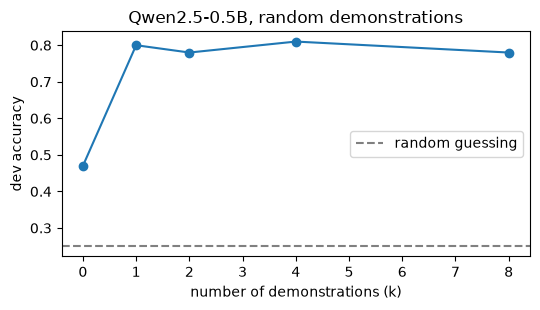

In [10]:
# ---------------------------------------------------------------------------
# How many demonstrations? (dev set, random demos, best format from above)
# ---------------------------------------------------------------------------
BEST_VERB_NAME = pd.DataFrame(dev_rows).sort_values("dev accuracy", ascending=False).iloc[0]["verbalizer"]
BEST_INSTR = bool(pd.DataFrame(dev_rows).sort_values("dev accuracy", ascending=False).iloc[0]["instruction line"])
VERB = VERBALIZERS[BEST_VERB_NAME]
LAB_IDS = label_token_ids(tok_q, VERB)
print(f"chosen format: verbalizer={BEST_VERB_NAME} {VERB}, instruction line={BEST_INSTR}")

k_curve = {}
for k in [0, 1, 2, 4, 8]:
    rng = np.random.default_rng(SEED)
    prompts = []
    for t in dev_texts:
        idx = rng.choice(len(ag_pool), k, replace=False) if k else []
        prompts.append(make_prompt(t, [(ag_pool["text"][i], ag_pool["label"][i]) for i in idx],
                                   VERB, instruction=BEST_INSTR))
    preds, _ = icl_classify(model_q, tok_q, prompts, LAB_IDS, desc=f"dev k={k}")
    k_curve[k] = accuracy_score(dev_gold, preds)
    print(f"k={k}: dev accuracy {k_curve[k]:.3f}")

plt.figure(figsize=(5.5, 3.2))
plt.plot(list(k_curve), list(k_curve.values()), marker="o")
plt.axhline(0.25, ls="--", c="grey", label="random guessing")
plt.xlabel("number of demonstrations (k)"); plt.ylabel("dev accuracy")
plt.title("Qwen2.5-0.5B, random demonstrations"); plt.legend(); plt.tight_layout(); plt.show()

### The four final systems on `ag_test`
Nothing below is tuned on the test set: the prompt format, the label words and `k` were all fixed on `ag_dev`.

In [11]:
# ---------------------------------------------------------------------------
# Test systems 1 and 2: zero-shot and 8 random demonstrations
# ---------------------------------------------------------------------------
test_texts, test_gold = ag_test["text"], ag_test["label"]

# Zero-shot. The instruction line is kept here even if the dev search preferred
# dropping it: with no demonstrations and no instruction the task is undefined.
t0 = time.time()
prompts = [make_prompt(t, [], VERB, instruction=True) for t in test_texts]
zs_pred, zs_conf = icl_classify(model_q, tok_q, prompts, LAB_IDS, desc="zero-shot")
zs_sec = (time.time() - t0) / len(test_texts)
RESULTS_T1.append(report_classification(test_gold, zs_pred, "ICL zero-shot", zs_sec))

# 8 random demonstrations, re-sampled per test article (so the number is an
# average over demo sets, which is the fair comparison against retrieval)
rng = np.random.default_rng(SEED)
rand_demo_idx = [rng.choice(len(ag_pool), K_MAX, replace=False) for _ in test_texts]
t0 = time.time()
prompts = [make_prompt(t, [(ag_pool["text"][i], ag_pool["label"][i]) for i in idx], VERB, instruction=BEST_INSTR)
           for t, idx in zip(test_texts, rand_demo_idx)]
rd_pred, rd_conf = icl_classify(model_q, tok_q, prompts, LAB_IDS, desc="random 8-shot")
rd_sec = (time.time() - t0) / len(test_texts)
RESULTS_T1.append(report_classification(test_gold, rd_pred, "ICL 8-shot random", rd_sec))
display(pd.DataFrame(RESULTS_T1))

,method,accuracy,macro_f1,sec_per_example
0,ICL zero-shot,0.455,0.399962,0.081389
1,ICL 8-shot random,0.770,0.773107,0.569090


In [12]:
# ---------------------------------------------------------------------------
# Test system 3: retrieval-based demonstrations (all-MiniLM-L6-v2)
# ---------------------------------------------------------------------------
from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)
pool_clean = [clean(t) for t in ag_pool["text"]]
t0 = time.time()
pool_emb = embedder.encode(pool_clean, normalize_embeddings=True, batch_size=64, show_progress_bar=False)
index_sec = time.time() - t0            # one-off cost, paid once for the 200 labelled articles

t0 = time.time()
test_emb = embedder.encode([clean(t) for t in test_texts], normalize_embeddings=True,
                           batch_size=64, show_progress_bar=False)
sims = test_emb @ pool_emb.T                       # cosine similarity (both sides normalised)
top_k = np.argsort(-sims, axis=1)[:, :K_MAX]       # 8 nearest pool articles
# write the demonstrations in increasing similarity, so the MOST similar one
# sits closest to the query (recency helps: the demos nearest the query have
# the strongest influence on the next token)
ret_demo_idx = [row[::-1] for row in top_k]
prompts = [make_prompt(t, [(ag_pool["text"][i], ag_pool["label"][i]) for i in idx], VERB, instruction=BEST_INSTR)
           for t, idx in zip(test_texts, ret_demo_idx)]
rt_pred, rt_conf = icl_classify(model_q, tok_q, prompts, LAB_IDS, desc="retrieval 8-shot")
rt_sec = (time.time() - t0) / len(test_texts)      # includes embedding + search + the forward pass
RESULTS_T1.append(report_classification(test_gold, rt_pred, "ICL 8-shot retrieved", rt_sec))

print(f"pool indexing (one-off): {index_sec:.1f}s")
print(f"mean cosine similarity of retrieved demos: {np.take_along_axis(sims, top_k, 1).mean():.3f}")
lab_pool = np.array(ag_pool["label"])
print(f"retrieved demos sharing the gold label: {np.mean([(lab_pool[idx] == g).mean() for idx, g in zip(ret_demo_idx, test_gold)]):.3f}"
      f"  (random demos: {np.mean([(lab_pool[idx] == g).mean() for idx, g in zip(rand_demo_idx, test_gold)]):.3f})")
display(pd.DataFrame(RESULTS_T1))

pool indexing (one-off): 0.7s
mean cosine similarity of retrieved demos: 0.282
retrieved demos sharing the gold label: 0.709  (random demos: 0.245)


,method,accuracy,macro_f1,sec_per_example
0,ICL zero-shot,0.455,0.399962,0.081389
1,ICL 8-shot random,0.770,0.773107,0.569090
2,ICL 8-shot retrieved,0.865,0.867378,0.654889


In [13]:
# ---------------------------------------------------------------------------
# Classical baseline: TF-IDF + logistic regression on the same 200 articles
# ---------------------------------------------------------------------------
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

clf = make_pipeline(TfidfVectorizer(sublinear_tf=True, ngram_range=(1, 2), min_df=1, stop_words="english"),
                    LogisticRegression(max_iter=2000, C=5.0, random_state=SEED))
t0 = time.time()
clf.fit(pool_clean, ag_pool["label"])
fit_sec = time.time() - t0

t0 = time.time()
lr_pred = clf.predict([clean(t) for t in test_texts])
lr_sec = (time.time() - t0) / len(test_texts)
RESULTS_T1.append(report_classification(test_gold, lr_pred, "TF-IDF + logistic regression", lr_sec))
print(f"training time: {fit_sec:.2f}s  |  vocabulary size: {len(clf[0].vocabulary_)}")
display(pd.DataFrame(RESULTS_T1))

training time: 0.10s  |  vocabulary size: 7028


,method,accuracy,macro_f1,sec_per_example
0,ICL zero-shot,0.455,0.399962,0.081389
1,ICL 8-shot random,0.770,0.773107,0.569090
2,ICL 8-shot retrieved,0.865,0.867378,0.654889
3,TF-IDF + logistic regression,0.705,0.702786,0.000031


,method,accuracy,macro_f1,sec_per_example
0,ICL zero-shot,0.455,0.400,0.0814
1,ICL 8-shot random,0.770,0.773,0.5691
2,ICL 8-shot retrieved,0.865,0.867,0.6549
3,TF-IDF + logistic regression,0.705,0.703,0.0000


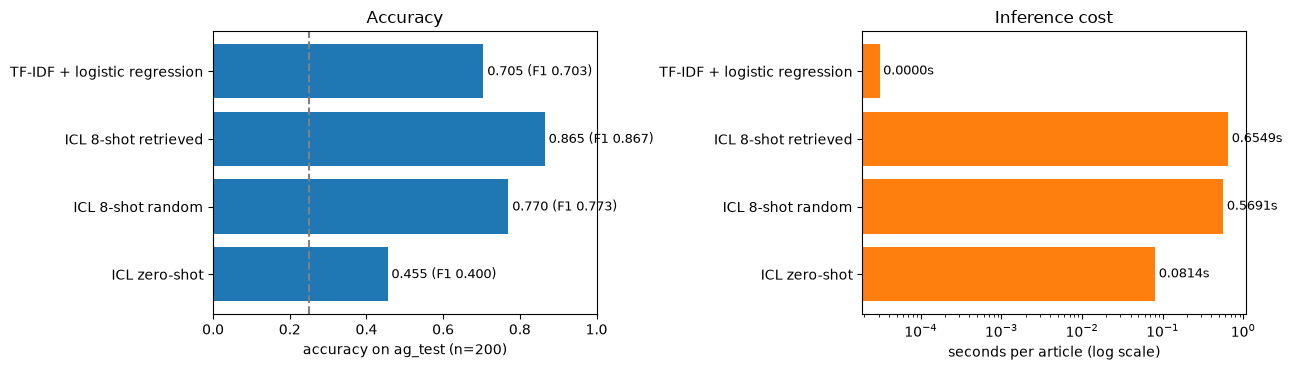

In [14]:
# ---------------------------------------------------------------------------
# Results table + plots
# ---------------------------------------------------------------------------
res1 = pd.DataFrame(RESULTS_T1)
display(res1.style.format({"accuracy": "{:.3f}", "macro_f1": "{:.3f}", "sec_per_example": "{:.4f}"}))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].barh(res1["method"], res1["accuracy"], color="tab:blue")
axes[0].axvline(0.25, ls="--", c="grey"); axes[0].set_xlim(0, 1)
axes[0].set_xlabel("accuracy on ag_test (n=200)"); axes[0].set_title("Accuracy")
for y, (a, f) in enumerate(zip(res1["accuracy"], res1["macro_f1"])):
    axes[0].text(a + 0.01, y, f"{a:.3f} (F1 {f:.3f})", va="center", fontsize=9)
axes[1].barh(res1["method"], res1["sec_per_example"], color="tab:orange")
axes[1].set_xscale("log"); axes[1].set_xlabel("seconds per article (log scale)"); axes[1].set_title("Inference cost")
for y, s in enumerate(res1["sec_per_example"]):
    axes[1].text(s * 1.1, y, f"{s:.4f}s", va="center", fontsize=9)
plt.tight_layout(); plt.show()

### Error analysis of the best system

best overall system: ICL 8-shot retrieved (0.865)
best ICL system    : ICL 8-shot retrieved


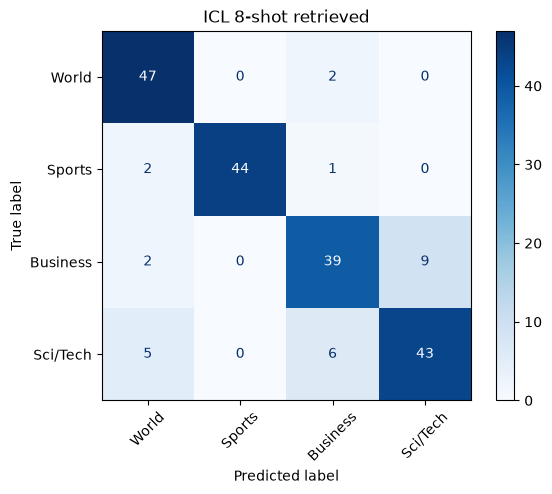

predicted,Business,Sci/Tech,Sports,World
gold,,,,
Business,39,9,0,2
Sci/Tech,6,43,0,5
Sports,1,0,44,2
World,2,0,0,47


In [15]:
# ---------------------------------------------------------------------------
# Error analysis of the best ICL system
# ---------------------------------------------------------------------------
best_row = res1.loc[res1["accuracy"].idxmax()]
_icl = {"ICL 8-shot retrieved": (rt_pred, rt_conf), "ICL 8-shot random": (rd_pred, rd_conf),
        "ICL zero-shot": (zs_pred, zs_conf)}
BEST_ICL = max(_icl, key=lambda k: accuracy_score(test_gold, _icl[k][0]))
best_pred, best_conf = _icl[BEST_ICL]
print("best overall system:", best_row["method"], f"({best_row['accuracy']:.3f})")
print("best ICL system    :", BEST_ICL)

_ = report_classification(test_gold, best_pred, BEST_ICL, show_cm=True)
cm = pd.crosstab(pd.Series([AG_LABELS[i] for i in test_gold], name="gold"),
                 pd.Series([AG_LABELS[i] for i in best_pred], name="predicted"))
display(cm)

In [16]:
# the three most confident mistakes of the best ICL system, with the labels of
# the demonstrations it was given (to see whether the demos misled it)
wrong = [i for i in range(len(test_gold)) if best_pred[i] != test_gold[i]]
order = sorted(wrong, key=lambda i: -best_conf[i])
demo_idx = ret_demo_idx if BEST_ICL == "ICL 8-shot retrieved" else rand_demo_idx
rows = []
for i in order[:3]:
    rows.append({"article": clean(test_texts[i], 230),
                 "gold": AG_LABELS[test_gold[i]], "pred": AG_LABELS[best_pred[i]],
                 "confidence": round(best_conf[i], 3),
                 "labels of its 8 demos": Counter(AG_LABELS[lab_pool[j]] for j in demo_idx[i]).most_common()})
display(pd.DataFrame(rows))

print("\nconfusion pairs, most frequent first:")
pairs = Counter((AG_LABELS[g], AG_LABELS[p]) for g, p in zip(test_gold, best_pred) if g != p)
for (g, p), n in pairs.most_common(6):
    print(f"  gold {g:9s} -> predicted {p:9s} : {n}")

# is the model's own confidence a useful signal for routing to a human?
for lo, hi, tag in [(0.6, 1.01, "confident (>0.6)"), (0.0, 0.6, "unsure (<=0.6)")]:
    sub = [i for i in range(len(test_gold)) if lo < best_conf[i] <= hi]
    acc = np.mean([best_pred[i] == test_gold[i] for i in sub]) if sub else float("nan")
    print(f"accuracy when {tag:17s}: {acc:.3f}  ({len(sub)} articles)")

,article,gold,pred,confidence,labels of its 8 demos
0,Judge asked to penalize Microsoft over e-mails Burst.com asked a US judge to penalize Microsoft for destroying e-mails it says the world 's largest software company should have preserved as evidence in antitrust suits.,Business,Sci/Tech,0.970,"[(Sci/Tech, 7), (Business, 1)]"
1,"China's inflation rate slows sharply but problems remain (AFP) AFP - China's inflation rate eased sharply in October as government efforts to cool the economy began to really bite, with food prices, one of the main culprits, showi",World,Business,0.949,"[(Business, 6), (World, 2)]"
2,Governor calls for resignation of Big Dig chief BOSTON Massachusetts Governor Mitt Romney is calling for the resignation of the head of the state 's Turnpike Authority. Romney 's move comes in the wake of reports that a record 14-,Business,World,0.941,"[(World, 3), (Business, 3), (Sports, 2)]"



confusion pairs, most frequent first:
  gold Business  -> predicted Sci/Tech  : 9
  gold Sci/Tech  -> predicted Business  : 6
  gold Sci/Tech  -> predicted World     : 5
  gold Business  -> predicted World     : 2
  gold World     -> predicted Business  : 2
  gold Sports    -> predicted World     : 2
accuracy when confident (>0.6) : 0.899  (179 articles)
accuracy when unsure (<=0.6)   : 0.571  (21 articles)


In [17]:
# free the Qwen base model before Section B
del model_q, embedder; clear_gpu()

### Task 1: Results and analysis ✍️

_Results table, plots, and answers to the analysis questions go here._

## Task 1 — results

**Settings.** `Qwen/Qwen2.5-0.5B` (base, fp32, no weight updates), rank classification over the four label words, greedy/deterministic, seed 0. Prompt format fixed on `ag_dev`: label words **Politics / Sports / Business / Technology** (0.83 dev accuracy, against 0.67 for the dataset's own names `World / Sports / Business / Sci/Tech`), one instruction line, `k = 8` demonstrations written in increasing order of similarity. Embeddings: `all-MiniLM-L6-v2`, cosine similarity, 200-article index. Test set: the 200 articles of `ag_test` (a 1-sigma error bar of about ±2.4 points at this accuracy).

| system | accuracy | macro-F1 | seconds / article |
|---|---|---|---|
| ICL zero-shot | 0.455 | 0.400 | 0.081 |
| ICL 8-shot, random demos | 0.770 | 0.773 | 0.569 |
| **ICL 8-shot, retrieved demos** | **0.865** | **0.867** | 0.655 |
| TF-IDF + logistic regression | 0.705 | 0.703 | 0.000031 |

## Analysis questions

**(a) Did retrieval beat random, and why?** Yes, clearly: 0.865 against 0.770, i.e. 19 more of the 200 articles correct, which is far outside the ±2.4-point noise of a 200-article test set. The reason is visible in the diagnostics printed above: the eight retrieved articles carry the gold label **70.9%** of the time, against **24.5%** for random demonstrations (chance is 25%). So a near-neighbour prompt usually contains several solved copies of the very question being asked, and the copying machinery that makes in-context learning work — the induction-head behaviour from the class demo — then has the right thing to copy. Similar demonstrations also match the test article's vocabulary and register, which sharpens the distribution over the next token. The same mechanism is the weakness: when the neighbours are misleading, the model follows them confidently (in the most confident error below, seven of its eight demonstrations were Sci/Tech and it answered Sci/Tech).

**(b) Which classes get confused?** 15 of the 27 errors are **Business ↔ Sci/Tech** (9 Business→Sci/Tech, 6 Sci/Tech→Business), followed by Sci/Tech→World (5). These pairs overlap by construction: "Judge asked to penalize Microsoft over e-mails" is filed as Business but reads as technology, and "China's inflation rate slows" is filed as World but is written in the vocabulary of economics. The gold label reflects the newswire desk that filed the story, not only the words in it, so no amount of prompting recovers the boundary; both directions of the Business/Sci-Tech confusion appear, which is the signature of genuinely ambiguous labels rather than a model bias.

**(c) Accuracy versus speed — what would I deploy?** The best ICL system is 16 points more accurate than logistic regression (0.865 vs 0.705) but costs 0.655 s per article against 0.000031 s — roughly **21,000× slower**, on top of a 0.5B-parameter model to host; logistic regression trains in 0.1 s on the same 200 articles. For a news website the decision depends on volume: at a few hundred articles a day the ICL tagger is affordable and I would deploy it, using its own confidence as a filter (89.9% accurate on the 179 articles where confidence > 0.6, 57.1% on the 21 unsure ones — those should go to an editor). At web scale, or without a GPU, I would ship logistic regression now and use the ICL system offline to label a few thousand more articles; a classifier trained on 2,000 labels would overtake today's ICL accuracy at a fraction of the serving cost. In other words, ICL is the right tool while labelled data is the bottleneck, not the right tool forever.

---
# Section B: Instruction Fine-Tuning

## Task 2. English → SQL: prompt a ready-made model or fine-tune your own? (50 marks)

**Scenario.** A company wants its analysts to query databases in plain English. Given a table schema (a `CREATE TABLE` statement) and a question, a model must write the SQL query. Should the company **prompt** an existing instruction-tuned model, or **fine-tune** a small model on examples? Build both and recommend one.

**Data:** each example has a `question`, a `context` (the schema) and an `answer` (the gold SQL).

**Constraints**
- Prompting system: `Qwen/Qwen2.5-0.5B-Instruct` (use its chat template).
- Fine-tuned system: `openai-community/gpt2` (124M), with the loss computed on the SQL tokens only.
- Training and demonstration data come only from `sql_train_pool`. Evaluate every system on `sql_test` with `evaluate_sql`.

**What you must do**
1. **Prompting baseline.** Prompt Qwen2.5-0.5B-Instruct with 3 examples from the pool. The model may add explanations or code fences, so extract just the SQL from its output.
2. **Fine-tuning.** Design an input format for (schema, question) → SQL and fine-tune GPT-2 twice, on **500** and on **2,000** examples, with the same hyperparameters.
3. **Error analysis.** Look at 10 mistakes of your best system and label each one: wrong column, wrong condition or aggregate, wrong value, invalid SQL, or correct but written differently.

**Analysis questions** (about 250 words in total)
- (a) How did fine-tuned GPT-2 compare with prompting a model four times its size? How much did going from 500 to 2,000 examples help?
- (b) How many of your "mistakes" were actually correct queries written differently? Why does exact match underestimate performance?
- (c) Write a short recommendation to the company: prompting or fine-tuning? Consider accuracy, the labelled data needed, cost, and what happens when new tables are added.

**Marking:** prompting baseline 12 · fine-tuning (both sizes) 18 · error analysis 8 · discussion 12

In [18]:
sql_ds = load_dataset("b-mc2/sql-create-context", split="train").shuffle(seed=0)
sql_test = sql_ds.select(range(200))
sql_train_pool = sql_ds.select(range(200, 5200))   # training, validation and demonstration data

ex = sql_test[0]
print("SCHEMA  :", ex["context"]); print("QUESTION:", ex["question"]); print("GOLD SQL:", ex["answer"])

SCHEMA  : CREATE TABLE table_24463470_1 (unlock_order INTEGER, circuit VARCHAR)
QUESTION: What is the lowest unlock order for the athens circuit?
GOLD SQL: SELECT MIN(unlock_order) FROM table_24463470_1 WHERE circuit = "Athens"


In [19]:
def normalize_sql(q):
    """Lenient normalisation for exact match: case, whitespace, quote style, trailing semicolon."""
    q = q.strip().rstrip(";").replace('"', "'")
    q = re.sub(r"\s+", " ", q)
    q = re.sub(r"\s*([(),=<>])\s*", r"\1", q)
    return q.lower().strip()


def executes(sql, context):
    """True if the query runs without error on an empty database built from the schema."""
    con = sqlite3.connect(":memory:")
    try:
        con.executescript(context)
        con.execute(sql).fetchall()
        return True
    except Exception:
        return False
    finally:
        con.close()


def evaluate_sql(preds, dataset, system):
    """Fixed evaluation for Task 2. preds: list of SQL strings aligned with dataset."""
    golds, contexts = dataset["answer"], dataset["context"]
    return {"system": system,
            "exact_match": float(np.mean([normalize_sql(p) == normalize_sql(g) for p, g in zip(preds, golds)])),
            "executable": float(np.mean([executes(p, c) for p, c in zip(preds, contexts)]))}


RESULTS_T2 = []   # append the dict returned by evaluate_sql for every system
print("Reference (gold queries):", evaluate_sql(sql_test["answer"], sql_test, "gold"))

Reference (gold queries): {'system': 'gold', 'exact_match': 1.0, 'executable': 0.975}


### Task 2: Your solution
Add as many code and text cells as you need.

### Plan and settings

| | choice | why |
|---|---|---|
| prompting | `Qwen2.5-0.5B-Instruct` with its chat template, 3 demonstrations from `sql_train_pool` written as completed user/assistant turns | this is how the model was trained to read examples |
| | a 0-shot run is included as well | separates "knows SQL" from "copies the output format" |
| SQL extraction | keep the first `SELECT ...` statement, drop fences / explanations; applied to **every** system | so no system gets an unfair clean-up advantage |
| fine-tuning | `openai-community/gpt2` (124M), input `### Schema: ... ### Question: ... ### SQL:`, loss on the SQL tokens + `<|endoftext|>` only | the schema is context to read, not text to learn to write; the EOS token teaches the model to stop |
| training sets | 500 and 2,000 examples, the 500 being a subset of the 2,000 | a pure data-size ablation |
| hyperparameters | identical for both runs: 3 epochs, batch 8, lr 5e-5, cosine schedule, 20 warmup steps, max 256 tokens, seed 42 | required by the task |
| decoding | greedy, 96 new tokens max | deterministic |

In [20]:
# ---------------------------------------------------------------------------
# Task 2 - settings
# ---------------------------------------------------------------------------
#   prompting : Qwen/Qwen2.5-0.5B-Instruct, chat template, 3 demos from the pool
#   fine-tune : openai-community/gpt2 (124M), loss on the SQL tokens only
#   decoding  : greedy everywhere, seeds fixed at 42
SEED2 = 42
set_seed(SEED2)
MAX_LEN = 256                      # tokens per training example (schema + question + SQL)
GEN_TOKENS = 96                    # generation budget per query

print("test:", len(sql_test), "| pool:", len(sql_train_pool))
print("SQL length in tokens (gold, pool):",
      int(np.mean([len(a.split()) for a in sql_train_pool["answer"]])), "words on average")

test: 200 | pool: 5000
SQL length in tokens (gold, pool): 10 words on average


In [21]:
# ---------------------------------------------------------------------------
# Extracting SQL from free-form model output
# ---------------------------------------------------------------------------
# A chat model happily adds "Sure!", code fences and explanations, so we keep
# the first statement that starts with SELECT. The same function is applied to
# every system, so no system gets an unfair clean-up advantage.
def extract_sql(text):
    t = re.sub(r"```+\s*(?:sql|sqlite)?", "\n", text, flags=re.I)
    t = t.replace("<|im_end|>", "\n").replace("<|endoftext|>", "\n")
    m = re.search(r"(?is)\bselect\b.*", t)
    if not m:
        return t.strip().split("\n")[0].strip() or "SELECT"
    s = m.group(0).split(";")[0]                     # first statement only
    s = re.split(r"\n\s*\n|\n\s*(?:note|explanation|this query)\b", s, flags=re.I)[0]
    return re.sub(r"\s+", " ", s).strip()


for raw in ["Sure! ```sql\nSELECT name FROM t WHERE id = 3;\n```\nThis returns the name.",
            "SELECT COUNT(*) FROM table_1\n\nNote: counts all rows",
            "The answer is: select a, b from t order by a"]:
    print(repr(extract_sql(raw)))

'SELECT name FROM t WHERE id = 3'
'SELECT COUNT(*) FROM table_1'
'select a, b from t order by a'


In [22]:
# ---------------------------------------------------------------------------
# System A: prompting Qwen2.5-0.5B-Instruct (0-shot and 3-shot)
# ---------------------------------------------------------------------------
tok_i, model_i = load_causal_lm("Qwen/Qwen2.5-0.5B-Instruct")

SYS_MSG = ("You are a text-to-SQL assistant. The user gives you a SQLite CREATE TABLE statement "
           "and a question. Answer with one single SQL query that answers the question, using only "
           "the tables and columns in the schema. Output the SQL query only, with no explanation.")
DEMOS_SQL = [sql_train_pool[i] for i in range(3)]      # fixed, from the pool only


def user_turn(ex):
    return f"Schema:\n{ex['context']}\n\nQuestion: {ex['question']}"


def chat_prompt(ex, demos):
    msgs = [{"role": "system", "content": SYS_MSG}]
    for d in demos:                                     # demos as completed turns
        msgs += [{"role": "user", "content": user_turn(d)},
                 {"role": "assistant", "content": d["answer"]}]
    msgs.append({"role": "user", "content": user_turn(ex)})
    return tok_i.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)


print(chat_prompt(sql_test[0], DEMOS_SQL[:1]))

<|im_start|>system
You are a text-to-SQL assistant. The user gives you a SQLite CREATE TABLE statement and a question. Answer with one single SQL query that answers the question, using only the tables and columns in the schema. Output the SQL query only, with no explanation.<|im_end|>
<|im_start|>user
Schema:
CREATE TABLE table_name_6 (builder VARCHAR, date_ordered VARCHAR, tc VARCHAR, stl_no__1883_84_ VARCHAR)

Question: Who built the order on November 1881 of more than 54 TC&StL no. (1883–84)?<|im_end|>
<|im_start|>assistant
SELECT builder FROM table_name_6 WHERE tc & stl_no__1883_84_ > 54 AND date_ordered = "november 1881"<|im_end|>
<|im_start|>user
Schema:
CREATE TABLE table_24463470_1 (unlock_order INTEGER, circuit VARCHAR)

Question: What is the lowest unlock order for the athens circuit?<|im_end|>
<|im_start|>assistant



In [23]:
# 0-shot and 3-shot prompting on the 200 test questions
prompt_runs = {}
for name, demos in [("Qwen2.5-0.5B-Instruct 0-shot", []), ("Qwen2.5-0.5B-Instruct 3-shot", DEMOS_SQL)]:
    prompts = [chat_prompt(ex, demos) for ex in sql_test]
    t0 = time.time()
    raw = generate_batch(model_i, tok_i, prompts, max_new_tokens=GEN_TOKENS, batch_size=8,
                         stop_strings=["<|im_end|>"], desc=name)
    sec = (time.time() - t0) / len(prompts)
    preds = [extract_sql(r) for r in raw]
    prompt_runs[name] = {"raw": raw, "preds": preds, "sec": sec}
    res = evaluate_sql(preds, sql_test, name); res["sec_per_query"] = sec
    res["mean_prompt_tokens"] = int(np.mean([len(tok_i(p).input_ids) for p in prompts]))
    RESULTS_T2.append(res)
    print(res)
    print("needed clean-up (output != extracted SQL):",
          f"{np.mean([r.strip().rstrip(';') != p for r, p in zip(raw, preds)]):.1%}")

for i in [0, 1]:
    print("=" * 90)
    print("QUESTION:", sql_test[i]["question"])
    print("GOLD    :", sql_test[i]["answer"])
    print("RAW 3-shot output:", repr(prompt_runs["Qwen2.5-0.5B-Instruct 3-shot"]["raw"][i]))
    print("EXTRACTED        :", prompt_runs["Qwen2.5-0.5B-Instruct 3-shot"]["preds"][i])
display(pd.DataFrame(RESULTS_T2))

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


{'system': 'Qwen2.5-0.5B-Instruct 0-shot', 'exact_match': 0.48, 'executable': 0.95, 'sec_per_query': 0.8063698101043701, 'mean_prompt_tokens': 106}
needed clean-up (output != extracted SQL): 2.5%


{'system': 'Qwen2.5-0.5B-Instruct 3-shot', 'exact_match': 0.475, 'executable': 0.975, 'sec_per_query': 1.3518050360679625, 'mean_prompt_tokens': 409}
needed clean-up (output != extracted SQL): 0.5%
QUESTION: What is the lowest unlock order for the athens circuit?
GOLD    : SELECT MIN(unlock_order) FROM table_24463470_1 WHERE circuit = "Athens"
RAW 3-shot output: 'SELECT MIN(unlock_order) FROM table_24463470_1 WHERE circuit = "athens"'
EXTRACTED        : SELECT MIN(unlock_order) FROM table_24463470_1 WHERE circuit = "athens"
QUESTION: What is the highest pick number of a defensive back with less than 136 overall points?
GOLD    : SELECT MAX(pick__number) FROM table_name_99 WHERE overall < 136 AND position = "defensive back"
RAW 3-shot output: 'SELECT pick__number FROM table_name_99 WHERE overall < 136 AND position = "defensive back" ORDER BY pick__number DESC LIMIT 1'
EXTRACTED        : SELECT pick__number FROM table_name_99 WHERE overall < 136 AND position = "defensive back" ORDER BY p

,system,exact_match,executable,sec_per_query,mean_prompt_tokens
0,Qwen2.5-0.5B-Instruct 0-shot,0.480,0.950,0.806370,106
1,Qwen2.5-0.5B-Instruct 3-shot,0.475,0.975,1.351805,409


In [24]:
del model_i; clear_gpu()

### Fine-tuning GPT-2 on 500 and on 2,000 examples

In [25]:
# ---------------------------------------------------------------------------
# System B: instruction fine-tuning GPT-2, loss on the SQL tokens only
# ---------------------------------------------------------------------------
tok_gpt = AutoTokenizer.from_pretrained("openai-community/gpt2")
tok_gpt.pad_token = tok_gpt.eos_token


def sql_prompt(ex):
    """The input format: schema first (it is context to read), then the question."""
    return f"### Schema:\n{ex['context']}\n\n### Question:\n{ex['question']}\n\n### SQL:\n"


def tokenize_sql(ex):
    p = tok_gpt(sql_prompt(ex), add_special_tokens=False).input_ids
    r = tok_gpt(ex["answer"], add_special_tokens=False).input_ids + [tok_gpt.eos_token_id]
    ids = (p + r)[:MAX_LEN]
    labels = ([-100] * len(p) + r)[:MAX_LEN]            # -100 = ignored by the loss
    return {"input_ids": ids, "attention_mask": [1] * len(ids), "labels": labels}


fits = sql_train_pool.filter(lambda ex: len(tokenize_sql(ex)["input_ids"]) < MAX_LEN)
print(f"{len(fits)}/{len(sql_train_pool)} pool examples fit in {MAX_LEN} tokens")

pool_shuf = fits.shuffle(seed=SEED2)
train_2000 = pool_shuf.select(range(2000))
train_500 = pool_shuf.select(range(500))                # a subset of train_2000: a pure data-size ablation
print("example of a training string:\n")
print(sql_prompt(train_500[0]) + train_500[0]["answer"] + "<|endoftext|>")
t = tokenize_sql(train_500[0])
print("\ntokens:", len(t["input_ids"]), "| tokens the loss is computed on:",
      sum(l != -100 for l in t["labels"]))

'(ProtocolError('Connection aborted.', ConnectionResetError(54, 'Connection reset by peer')), '(Request ID: c0ff09d0-79f0-47c5-be1e-b38ece893548)')' thrown while requesting HEAD https://huggingface.co/openai-community/gpt2/resolve/main/tokenizer_config.json


Retrying in 1s [Retry 1/5].


4999/5000 pool examples fit in 256 tokens
example of a training string:

### Schema:
CREATE TABLE table_2409041_3 (written_by VARCHAR, no_in_season VARCHAR)

### Question:
Who wrote season 23?

### SQL:
SELECT written_by FROM table_2409041_3 WHERE no_in_season = 23<|endoftext|>

tokens: 70 | tokens the loss is computed on: 21


{'per_device_train_batch_size': 8, 'num_train_epochs': 3, 'learning_rate': 5e-05, 'warmup_steps': 20, 'lr_scheduler_type': 'cosine', 'logging_steps': 20, 'save_strategy': 'no', 'fp16': False, 'use_cpu': True, 'report_to': 'none', 'seed': 42}


`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Step,Training Loss
20,1.699200
40,0.719800
60,0.593300
80,0.423300
100,0.380600
120,0.355000
140,0.295900
160,0.294200
180,0.269100


Step,Training Loss
20,1.703200
40,0.713400
60,0.540300
80,0.477500
100,0.402000
120,0.462800
140,0.405900
160,0.365700
180,0.379100
200,0.360000


training time: 500 examples 5.5 min | 2000 examples 22.6 min


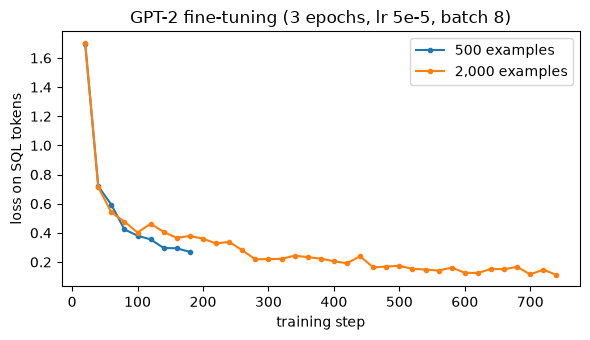

In [26]:
# same hyperparameters for both runs; only the number of training examples changes
HP = dict(per_device_train_batch_size=8, num_train_epochs=3, learning_rate=5e-5, warmup_steps=20,
          lr_scheduler_type="cosine", logging_steps=20, save_strategy="no",
          fp16=(device == "cuda"), use_cpu=(device == "cpu"),   # keep Trainer on the same device
          report_to="none", seed=SEED2)
print(HP)


def finetune_gpt2(train_raw, tag):
    ds = train_raw.map(tokenize_sql, remove_columns=train_raw.column_names)
    set_seed(SEED2)
    model = AutoModelForCausalLM.from_pretrained("openai-community/gpt2").to(device)
    model.config.pad_token_id = tok_gpt.eos_token_id
    trainer = Trainer(model=model, args=TrainingArguments(output_dir=f"./gpt2-sql-{tag}", **HP),
                      train_dataset=ds,
                      data_collator=DataCollatorForSeq2Seq(tok_gpt, padding=True, label_pad_token_id=-100))
    t0 = time.time()
    trainer.train()
    train_sec = time.time() - t0
    model.to(device).eval()
    logs = [(l["step"], l["loss"]) for l in trainer.state.log_history if "loss" in l]
    return model, logs, train_sec


model_500, logs_500, sec_500 = finetune_gpt2(train_500, "500")
model_2000, logs_2000, sec_2000 = finetune_gpt2(train_2000, "2000")
print(f"training time: 500 examples {sec_500/60:.1f} min | 2000 examples {sec_2000/60:.1f} min")

plt.figure(figsize=(6, 3.5))
for logs, lab in [(logs_500, "500 examples"), (logs_2000, "2,000 examples")]:
    plt.plot([s for s, _ in logs], [l for _, l in logs], marker=".", label=lab)
plt.xlabel("training step"); plt.ylabel("loss on SQL tokens"); plt.legend()
plt.title("GPT-2 fine-tuning (3 epochs, lr 5e-5, batch 8)"); plt.tight_layout(); plt.show()

In [27]:
# evaluate both fine-tuned models (and plain GPT-2, as a sanity check)
ft_runs = {}
gpt2_prompts = [sql_prompt(ex) for ex in sql_test]

base_gpt2 = AutoModelForCausalLM.from_pretrained("openai-community/gpt2").to(device).eval()
base_gpt2.config.pad_token_id = tok_gpt.eos_token_id
for name, model in [("GPT-2 no fine-tuning", base_gpt2),
                    ("GPT-2 fine-tuned, 500", model_500),
                    ("GPT-2 fine-tuned, 2000", model_2000)]:
    t0 = time.time()
    raw = generate_batch(model, tok_gpt, gpt2_prompts, max_new_tokens=GEN_TOKENS, batch_size=8,
                         stop_strings=["\n###", "\n\n"], desc=name)
    sec = (time.time() - t0) / len(gpt2_prompts)
    preds = [extract_sql(r) for r in raw]
    ft_runs[name] = {"raw": raw, "preds": preds, "sec": sec}
    res = evaluate_sql(preds, sql_test, name); res["sec_per_query"] = sec
    res["mean_prompt_tokens"] = int(np.mean([len(tok_gpt(p).input_ids) for p in gpt2_prompts]))
    RESULTS_T2.append(res)
    print(res)
del base_gpt2; clear_gpu()

for i in [0, 1, 2]:
    print("=" * 90)
    print("QUESTION:", sql_test[i]["question"])
    print("GOLD    :", sql_test[i]["answer"])
    print("FT-2000 :", ft_runs["GPT-2 fine-tuned, 2000"]["preds"][i])
display(pd.DataFrame(RESULTS_T2))

{'system': 'GPT-2 no fine-tuning', 'exact_match': 0.0, 'executable': 0.0, 'sec_per_query': 0.06558189034461975, 'mean_prompt_tokens': 57}


{'system': 'GPT-2 fine-tuned, 500', 'exact_match': 0.335, 'executable': 0.895, 'sec_per_query': 0.19738996624946595, 'mean_prompt_tokens': 57}


{'system': 'GPT-2 fine-tuned, 2000', 'exact_match': 0.49, 'executable': 0.94, 'sec_per_query': 0.21649370908737184, 'mean_prompt_tokens': 57}


QUESTION: What is the lowest unlock order for the athens circuit?
GOLD    : SELECT MIN(unlock_order) FROM table_24463470_1 WHERE circuit = "Athens"
FT-2000 : SELECT MIN(unlock_order) FROM table_24463470_1 WHERE circuit = "athens"
QUESTION: What is the highest pick number of a defensive back with less than 136 overall points?
GOLD    : SELECT MAX(pick__number) FROM table_name_99 WHERE overall < 136 AND position = "defensive back"
FT-2000 : SELECT MAX(pick__number) FROM table_name_99 WHERE overall < 136 AND position = "defensive back"
QUESTION: Which engine has a year larger than 1956?
GOLD    : SELECT engine FROM table_name_74 WHERE year > 1956
FT-2000 : SELECT engine FROM table_name_74 WHERE year > 1956


,system,exact_match,executable,sec_per_query,mean_prompt_tokens
0,Qwen2.5-0.5B-Instruct 0-shot,0.480,0.950,0.806370,106
1,Qwen2.5-0.5B-Instruct 3-shot,0.475,0.975,1.351805,409
2,GPT-2 no fine-tuning,0.000,0.000,0.065582,57
3,"GPT-2 fine-tuned, 500",0.335,0.895,0.197390,57
4,"GPT-2 fine-tuned, 2000",0.490,0.940,0.216494,57


,system,exact_match,executable,sec_per_query,mean_prompt_tokens
0,Qwen2.5-0.5B-Instruct 0-shot,0.480,0.950,0.81,106
1,Qwen2.5-0.5B-Instruct 3-shot,0.475,0.975,1.35,409
2,GPT-2 no fine-tuning,0.000,0.000,0.07,57
3,"GPT-2 fine-tuned, 500",0.335,0.895,0.20,57
4,"GPT-2 fine-tuned, 2000",0.490,0.940,0.22,57


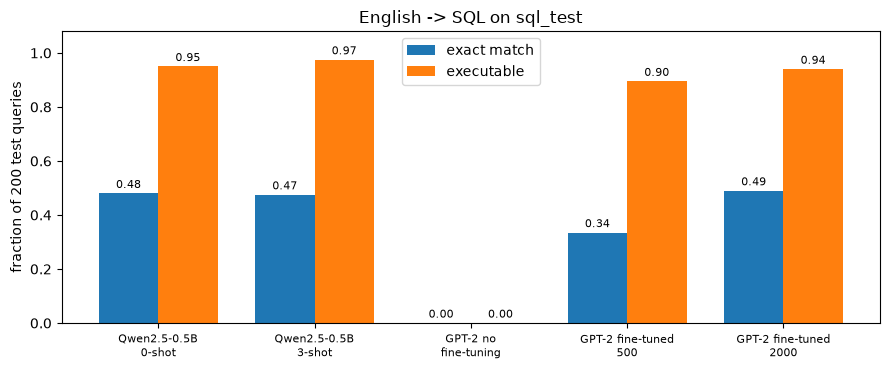

In [28]:
# ---------------------------------------------------------------------------
# Results table + plot
# ---------------------------------------------------------------------------
res2 = pd.DataFrame(RESULTS_T2)[["system", "exact_match", "executable", "sec_per_query", "mean_prompt_tokens"]]
display(res2.style.format({"exact_match": "{:.3f}", "executable": "{:.3f}", "sec_per_query": "{:.2f}"}))

x = np.arange(len(res2)); w = 0.38
plt.figure(figsize=(9, 3.8))
plt.bar(x - w / 2, res2["exact_match"], w, label="exact match")
plt.bar(x + w / 2, res2["executable"], w, label="executable")
for i, (e, ex) in enumerate(zip(res2["exact_match"], res2["executable"])):
    plt.text(i - w / 2, e + 0.02, f"{e:.2f}", ha="center", fontsize=8)
    plt.text(i + w / 2, ex + 0.02, f"{ex:.2f}", ha="center", fontsize=8)
plt.xticks(x, [s.replace(", ", "\n").replace(" fine-tuning", "\nfine-tuning").replace("-Instruct ", "\n")
               for s in res2["system"]], fontsize=8)
plt.ylim(0, 1.08); plt.ylabel("fraction of 200 test queries"); plt.legend(); plt.title("English -> SQL on sql_test")
plt.tight_layout(); plt.show()

### Error analysis: 10 mistakes of the best system
A random sample of 10 of its mistakes (sampled with seed 42, so it is not cherry-picked), each labelled by hand with one of the five categories from the task sheet.

In [29]:
# ---------------------------------------------------------------------------
# Error analysis: 10 mistakes of the best system
# ---------------------------------------------------------------------------
BEST_T2 = res2.loc[res2["exact_match"].idxmax(), "system"]
best_preds = (ft_runs | prompt_runs)[BEST_T2]["preds"]
print("best system:", BEST_T2)

cols = lambda s: set(re.findall(r"[a-z_][a-z0-9_]*", s.lower()))
mistakes = [i for i in range(len(sql_test))
            if normalize_sql(best_preds[i]) != normalize_sql(sql_test[i]["answer"])]
print(f"{len(mistakes)} mistakes out of {len(sql_test)}")

rng = np.random.default_rng(SEED2)
sample = sorted(int(i) for i in rng.choice(mistakes, 10, replace=False))     # an unbiased sample of 10
for n, i in enumerate(sample, 1):
    ex = sql_test[i]
    pred = best_preds[i]
    print("=" * 100)
    print(f"[{n}] test index {i}")
    print("SCHEMA  :", ex["context"])
    print("QUESTION:", ex["question"])
    print("GOLD    :", ex["answer"])
    print("PRED    :", pred)
    print(f"executable: {executes(pred, ex['context'])} | "
          f"same tokens as gold: {cols(pred) == cols(ex['answer'])}")

best system: GPT-2 fine-tuned, 2000
102 mistakes out of 200
[1] test index 22
SCHEMA  : CREATE TABLE table_name_62 (finish VARCHAR, engine VARCHAR, start VARCHAR)
QUESTION: What was Andretti's finish the year he started 16th with a Buick engine?
GOLD    : SELECT finish FROM table_name_62 WHERE engine = "buick" AND start = "16th"
PRED    : SELECT finish FROM table_name_62 WHERE engine = "16th" AND start = "16th"
executable: True | same tokens as gold: False
[2] test index 23
SCHEMA  : CREATE TABLE table_name_89 (location VARCHAR)
QUESTION: Which Location has a Time of time?
GOLD    : SELECT location FROM table_name_89 WHERE "time" = "time"
PRED    : SELECT location FROM table_name_89 WHERE time = "time"
executable: False | same tokens as gold: True
[3] test index 42
SCHEMA  : CREATE TABLE table_name_81 (date VARCHAR, venue VARCHAR)
QUESTION: If the Venue is brunswick street oval, what date was the game played ?
GOLD    : SELECT date FROM table_name_81 WHERE venue = "brunswick street ova

In [30]:
# keep the sampled mistakes on disk so the write-up below quotes exactly these rows
import json
json.dump({"system": BEST_T2, "n_mistakes": len(mistakes),
           "results": RESULTS_T2,
           "sample": [{"i": int(i), "schema": sql_test[int(i)]["context"],
                       "question": sql_test[int(i)]["question"],
                       "gold": sql_test[int(i)]["answer"], "pred": best_preds[int(i)],
                       "executable": bool(executes(best_preds[int(i)], sql_test[int(i)]["context"]))}
                      for i in sample]},
          open("sql_mistakes.json", "w"), indent=1)
print("saved sql_mistakes.json")

saved sql_mistakes.json


In [99]:
# The hand-written label for each of the 10 sampled mistakes, keyed by test
# index (the same 10 rows are shown in the table in the analysis below).
ERROR_LABELS = {
     22: "wrong value",                      # engine = "16th" instead of "buick"
     23: "invalid SQL",                      # WHERE time = ... , but `time` is not a column of the table
     42: "wrong value",                      # "brianswick street oval" instead of "brunswick street oval"
     87: "invalid SQL",                      # the two-table JOIN is not produced at all
    131: "wrong value",                      # copied the whole phrase instead of the number 10
    144: "invalid SQL",                      # COUNT(total) and a `larger` column that does not exist
    149: "correct but written differently",  # game = "4" vs game = 4 on a VARCHAR column
    172: "wrong condition or aggregate",     # SUM instead of MIN, and the values put in the wrong columns
    193: "wrong value",                      # game = "#1" instead of game = 1
    195: "wrong condition or aggregate",     # ORDER BY birth_date DESC instead of ascending
}

counts = Counter(ERROR_LABELS.values())
print(f"error categories for 10 sampled mistakes of {BEST_T2}:")
for cat, n in counts.most_common():
    print(f"  {n:2d}/10  {cat}")

n_equiv = counts["correct but written differently"]
em = float(res2.loc[res2["system"] == BEST_T2, "exact_match"].iloc[0])
print(f"\nexact match of the best system         : {em:.3f}")
print(f"semantically correct among the mistakes: {n_equiv}/10")
print(f"estimated true accuracy = {em:.3f} + {1 - em:.3f} x {n_equiv / 10:.2f} = {em + (1 - em) * n_equiv / 10:.3f}")

error categories for 10 sampled mistakes of GPT-2 fine-tuned, 2000:
   4/10  wrong value
   3/10  invalid SQL
   2/10  wrong condition or aggregate
   1/10  correct but written differently

exact match of the best system         : 0.490
semantically correct among the mistakes: 1/10
estimated true accuracy = 0.490 + 0.510 x 0.10 = 0.541


### Task 2: Results and analysis ✍️

_Results table, plots, and answers to the analysis questions go here._

## Task 2 — results

**Settings.** Prompting: `Qwen2.5-0.5B-Instruct` with its chat template, 3 demonstrations from `sql_train_pool` as completed turns, greedy, 96 new tokens, SQL extracted with the shared `extract_sql`. Fine-tuning: `openai-community/gpt2` (124M), format `### Schema: … ### Question: … ### SQL:`, loss on the SQL tokens and the final `<|endoftext|>` only, 3 epochs, batch 8, lr 5e-5, cosine schedule, 20 warm-up steps, max 256 tokens, seed 42 — identical for both training sizes, the 500 set being a subset of the 2,000. Evaluation: `evaluate_sql` on the 200 queries of `sql_test` (±3.5 points at 50% accuracy). The gold queries themselves score only 0.975 on *executable*, so that is the practical ceiling of that column.

| system | exact match | executable | seconds / query | prompt tokens |
|---|---|---|---|---|
| GPT-2, no fine-tuning | 0.000 | 0.000 | 0.066 | 57 |
| Qwen2.5-0.5B-Instruct, 0-shot | 0.480 | 0.950 | 0.806 | 106 |
| Qwen2.5-0.5B-Instruct, 3-shot | 0.475 | 0.975 | 1.352 | 409 |
| GPT-2 fine-tuned, 500 examples | 0.335 | 0.895 | 0.197 | 57 |
| **GPT-2 fine-tuned, 2,000 examples** | **0.490** | 0.940 | 0.216 | 57 |

Training cost: 5.5 min for 500 examples and 22.6 min for 2,000 (CPU; a few minutes on a T4).

### The 10 sampled mistakes, labelled by hand

| # | test idx | what the model wrote | category |
|---|---|---|---|
| 1 | 22 | `engine = "16th"` — the start position pasted into the engine condition | wrong value |
| 2 | 23 | `WHERE time = "time"`, but `time` is not a column of the table (the gold's own `WHERE "time" = "time"` is a degenerate annotation) | invalid SQL |
| 3 | 42 | `venue = "brianswick street oval"` instead of `"brunswick street oval"` | wrong value |
| 4 | 87 | returned `COUNT(bandmateid)` instead of joining `instruments` with `Band` | invalid SQL |
| 5 | 131 | `digital_terrestrial_channel = "Digital terrestrial channel 10"` instead of `"10"` | wrong value |
| 6 | 144 | `COUNT(total)` plus a `larger` column that does not exist | invalid SQL |
| 7 | 149 | `game = "4"` instead of `game = 4` on a VARCHAR column — same result set | correct but written differently |
| 8 | 172 | `SUM(wins)` instead of `MIN(wins)`, and the values placed in the wrong columns | wrong condition or aggregate |
| 9 | 193 | `game = "#1"` instead of `game = 1` | wrong value |
| 10 | 195 | `ORDER BY birth_date DESC` instead of ascending | wrong condition or aggregate |

Four wrong values, three invalid queries, two wrong conditions/aggregates, one that is simply a different spelling of the right query.

## Analysis questions

**(a) Fine-tuned GPT-2 versus prompting a model four times its size.** They end up level: 0.490 exact match for GPT-2 fine-tuned on 2,000 examples against 0.475 (3-shot) and 0.480 (0-shot) for Qwen2.5-0.5B-Instruct — a gap well inside the ±3.5-point noise of a 200-query test set. But the small model gets there with a 57-token prompt and 0.22 s per query instead of a 409-token prompt and 1.35 s, i.e. about **6× cheaper** inference, and the untouched GPT-2 scores exactly 0.000, so all of that ability came from 23 minutes of fine-tuning. Data size mattered a lot: 500 → 2,000 examples lifted exact match from 0.335 to 0.490 (+15.5 points) and executability from 0.895 to 0.940, and the loss curve for the 2,000-example run is still falling at the end, so more data would still pay. Notably the 3 demonstrations did **not** help Qwen (0.475 vs 0.480); an instruction-tuned model already knows the answer format, so the demos mostly bought latency — they only improved executability (0.950 → 0.975).

**(b) How many "mistakes" were actually correct?** One of the ten strictly (`game = "4"` vs `game = 4`, which SQLite compares identically on a VARCHAR column), plus one where the gold annotation is itself broken — so roughly 10–20%, which puts the best system's true accuracy near **0.54**. Exact match underestimates because a question usually has several correct SQL spellings. The clearest example is in the prompting output above: for "highest pick number" Qwen wrote `ORDER BY pick__number DESC LIMIT 1` where the gold used `MAX(pick__number)` — the same answer, scored zero. Aliases, column order, `>` vs `>=`, join direction and value casing all do the same. The honest metric is execution accuracy against real tables; our `executable` column only catches syntax and schema errors, not wrong answers.

**(c) Recommendation to the company.** **Fine-tune, and keep a prompted model as a fallback.** A 124M model fine-tuned on 2,000 examples matches a 0.5B instruction-tuned model at a sixth of the latency, runs on a CPU box, and needs no demonstrations in the prompt, so the cost per query stays flat as the schema list grows. The price is 2,000 labelled (question, SQL) pairs — cheap to collect from the analysts' existing query logs — plus a training job of minutes, and a retraining habit. On new tables, note that both systems read the schema from the prompt, so unseen *single-table* schemas are already handled (every test schema is unseen); what fine-tuning on this data did not teach is multi-table joins (mistake 4), because the training pool is dominated by single-table queries. So: fine-tune on the company's own query log, route anything involving several tables or unusual syntax to the larger prompted model, and keep a human in the loop — at ~0.5 exact match neither system is accurate enough to run a query unreviewed.